In [2]:
# ==============================================================================
# PHASE 6: SWIN TRANSFORMER TINY DEEP LEARNING MODEL TRAINING PIPELINE
# CELL 1: ENVIRONMENT SETUP, GPU AUDIT & HYPERPARAMETER SPECIFICATION
# ==============================================================================
import os
import sys
import random
import json
import numpy as np
import pandas as pd
import torch
import torchvision

# ------------------------------------------------------------------------------
# 1. Deterministic Reproducibility Seeding
# ------------------------------------------------------------------------------
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# ------------------------------------------------------------------------------
# 2. Project Directory Resolution
# ------------------------------------------------------------------------------
# Resolve project root dynamically whether run from workspace or Notebooks dir
cwd = os.getcwd()
if os.path.basename(cwd).lower() == "notebooks":
    PROJECT_ROOT = os.path.abspath(os.path.join(cwd, ".."))
else:
    PROJECT_ROOT = os.path.abspath(cwd)

SPLITS_DIR = os.path.join(PROJECT_ROOT, "metadata", "splits")
PROCESSED_DATA_DIR = os.path.join(PROJECT_ROOT, "datasets", "processed_384")
CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "Models", "checkpoints", "swin_tiny")
LOGS_DIR = os.path.join(PROJECT_ROOT, "Models", "logs", "swin_tiny")
PLOTS_DIR = os.path.join(PROJECT_ROOT, "results", "plots", "swin_training")

for d in [CHECKPOINTS_DIR, LOGS_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ------------------------------------------------------------------------------
# 3. Hardware Compute Audit
# ------------------------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (CPU)"
gpu_vram = torch.cuda.get_device_properties(0).total_memory / (1024**3) if torch.cuda.is_available() else 0.0

# ------------------------------------------------------------------------------
# 4. Centralized Hyperparameters & Checkpointing Configuration
# ------------------------------------------------------------------------------
CONFIG = {
    "project_root": PROJECT_ROOT,
    "model_name": "swin_tiny",
    "num_classes": 25,
    "input_size": (384, 384),
    "batch_size": 16,
    "epochs": 25,
    "learning_rate": 1e-4,
    "min_lr": 1e-6,
    "weight_decay": 0.05,            # Standard for Vision Transformers (decoupled AdamW)
    "warmup_epochs": 2,
    "label_smoothing": 0.1,
    "mixed_precision": True,          # Leverages RTX 5050 FP16 Tensor Cores
    "grad_clip_norm": 1.0,
    "num_workers": 0,                 # Safe execution under Windows OS
    "resume": True,
    "checkpoints_dir": CHECKPOINTS_DIR,
    "last_checkpoint_path": os.path.join(CHECKPOINTS_DIR, "last_checkpoint.pth"),
    "best_checkpoint_path": os.path.join(CHECKPOINTS_DIR, "best_swin_tiny.pth"),
    "logs_dir": LOGS_DIR,
    "plots_dir": PLOTS_DIR
}

# ------------------------------------------------------------------------------
# 5. Manifest Integrity Verification
# ------------------------------------------------------------------------------
train_manifest_path = os.path.join(SPLITS_DIR, "train_manifest.csv")
val_manifest_path = os.path.join(SPLITS_DIR, "val_manifest.csv")
test_manifest_path = os.path.join(SPLITS_DIR, "test_manifest.csv")

assert os.path.exists(train_manifest_path), f"Missing {train_manifest_path}"
assert os.path.exists(val_manifest_path), f"Missing {val_manifest_path}"
assert os.path.exists(test_manifest_path), f"Missing {test_manifest_path}"

df_train_meta = pd.read_csv(train_manifest_path)
df_val_meta = pd.read_csv(val_manifest_path)
df_test_meta = pd.read_csv(test_manifest_path)

print("=" * 80)
print("  PHASE 6: SWIN TRANSFORMER TINY DEEP LEARNING MODEL PIPELINE")
print("=" * 80)
print(f"✓ Project Root         : {PROJECT_ROOT}")
print(f"✓ Training Dataset     : {len(df_train_meta):,} images (64.0%)")
print(f"✓ Validation Dataset   : {len(df_val_meta):,} images (16.0%)")
print(f"✓ Test Holdout Dataset : {len(df_test_meta):,} images (20.0%) [Strictly Isolated]")
print(f"✓ Total Classes        : {CONFIG['num_classes']} diagnostic categories")
print(f"✓ Checkpoints Directory: {CHECKPOINTS_DIR}")
print(f"✓ Resumable Training   : Enabled (Tracks last & best checkpoints)")
print("-" * 80)
print(f"✓ Active Compute Device: {DEVICE.type}")
print(f"✓ GPU Accelerator      : {gpu_name}")
print(f"✓ GPU Dedicated VRAM   : {gpu_vram:.2f} GB")
print(f"✓ Mixed Precision (AMP): Enabled (torch.amp for RTX 5050 Tensor Cores)")
print(f"✓ Windows DataLoaders  : num_workers = 0 (Safe from deadlock/broken pipe)")
print("-" * 80)
print("✓ Hyperparameter Setup :")
for k, v in CONFIG.items():
    print(f"    - {k:<20}: {v}")
print("=" * 80)
print("Ready for Cell 2: Clinical DataLoaders & Class-Balanced Effective Sample Weights.")

  PHASE 6: SWIN TRANSFORMER TINY DEEP LEARNING MODEL PIPELINE
✓ Project Root         : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project
✓ Training Dataset     : 14,713 images (64.0%)
✓ Validation Dataset   : 3,679 images (16.0%)
✓ Test Holdout Dataset : 4,599 images (20.0%) [Strictly Isolated]
✓ Total Classes        : 25 diagnostic categories
✓ Checkpoints Directory: c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\swin_tiny
✓ Resumable Training   : Enabled (Tracks last & best checkpoints)
--------------------------------------------------------------------------------
✓ Active Compute Device: cuda
✓ GPU Accelerator      : NVIDIA GeForce RTX 5050 Laptop GPU
✓ GPU Dedicated VRAM   : 7.96 GB
✓ Mixed Precision (AMP): Enabled (torch.amp for RTX 5050 Tensor Cores)
✓ Windows DataLoaders  : num_workers = 0 (Safe from deadlock/broken pipe)
-----------------------------------------------

  BUILDING CLINICAL DATA PIPELINE & CLASS-BALANCED WEIGHTS
✓ Diagnostic Categories Loaded : 25 classes
✓ Acuity Tiers Mapped          : 25 categories
✓ Class Weights Computed       : Scaled from 0.25x (Melanoma) to 7.61x (Kaposi Sarcoma)
✓ Train DataLoader Created     : 919 batches (14,713 images)
✓ Val DataLoader Created       : 230 batches (3,679 images)
✓ Test DataLoader Created      : 288 batches (4,599 images)


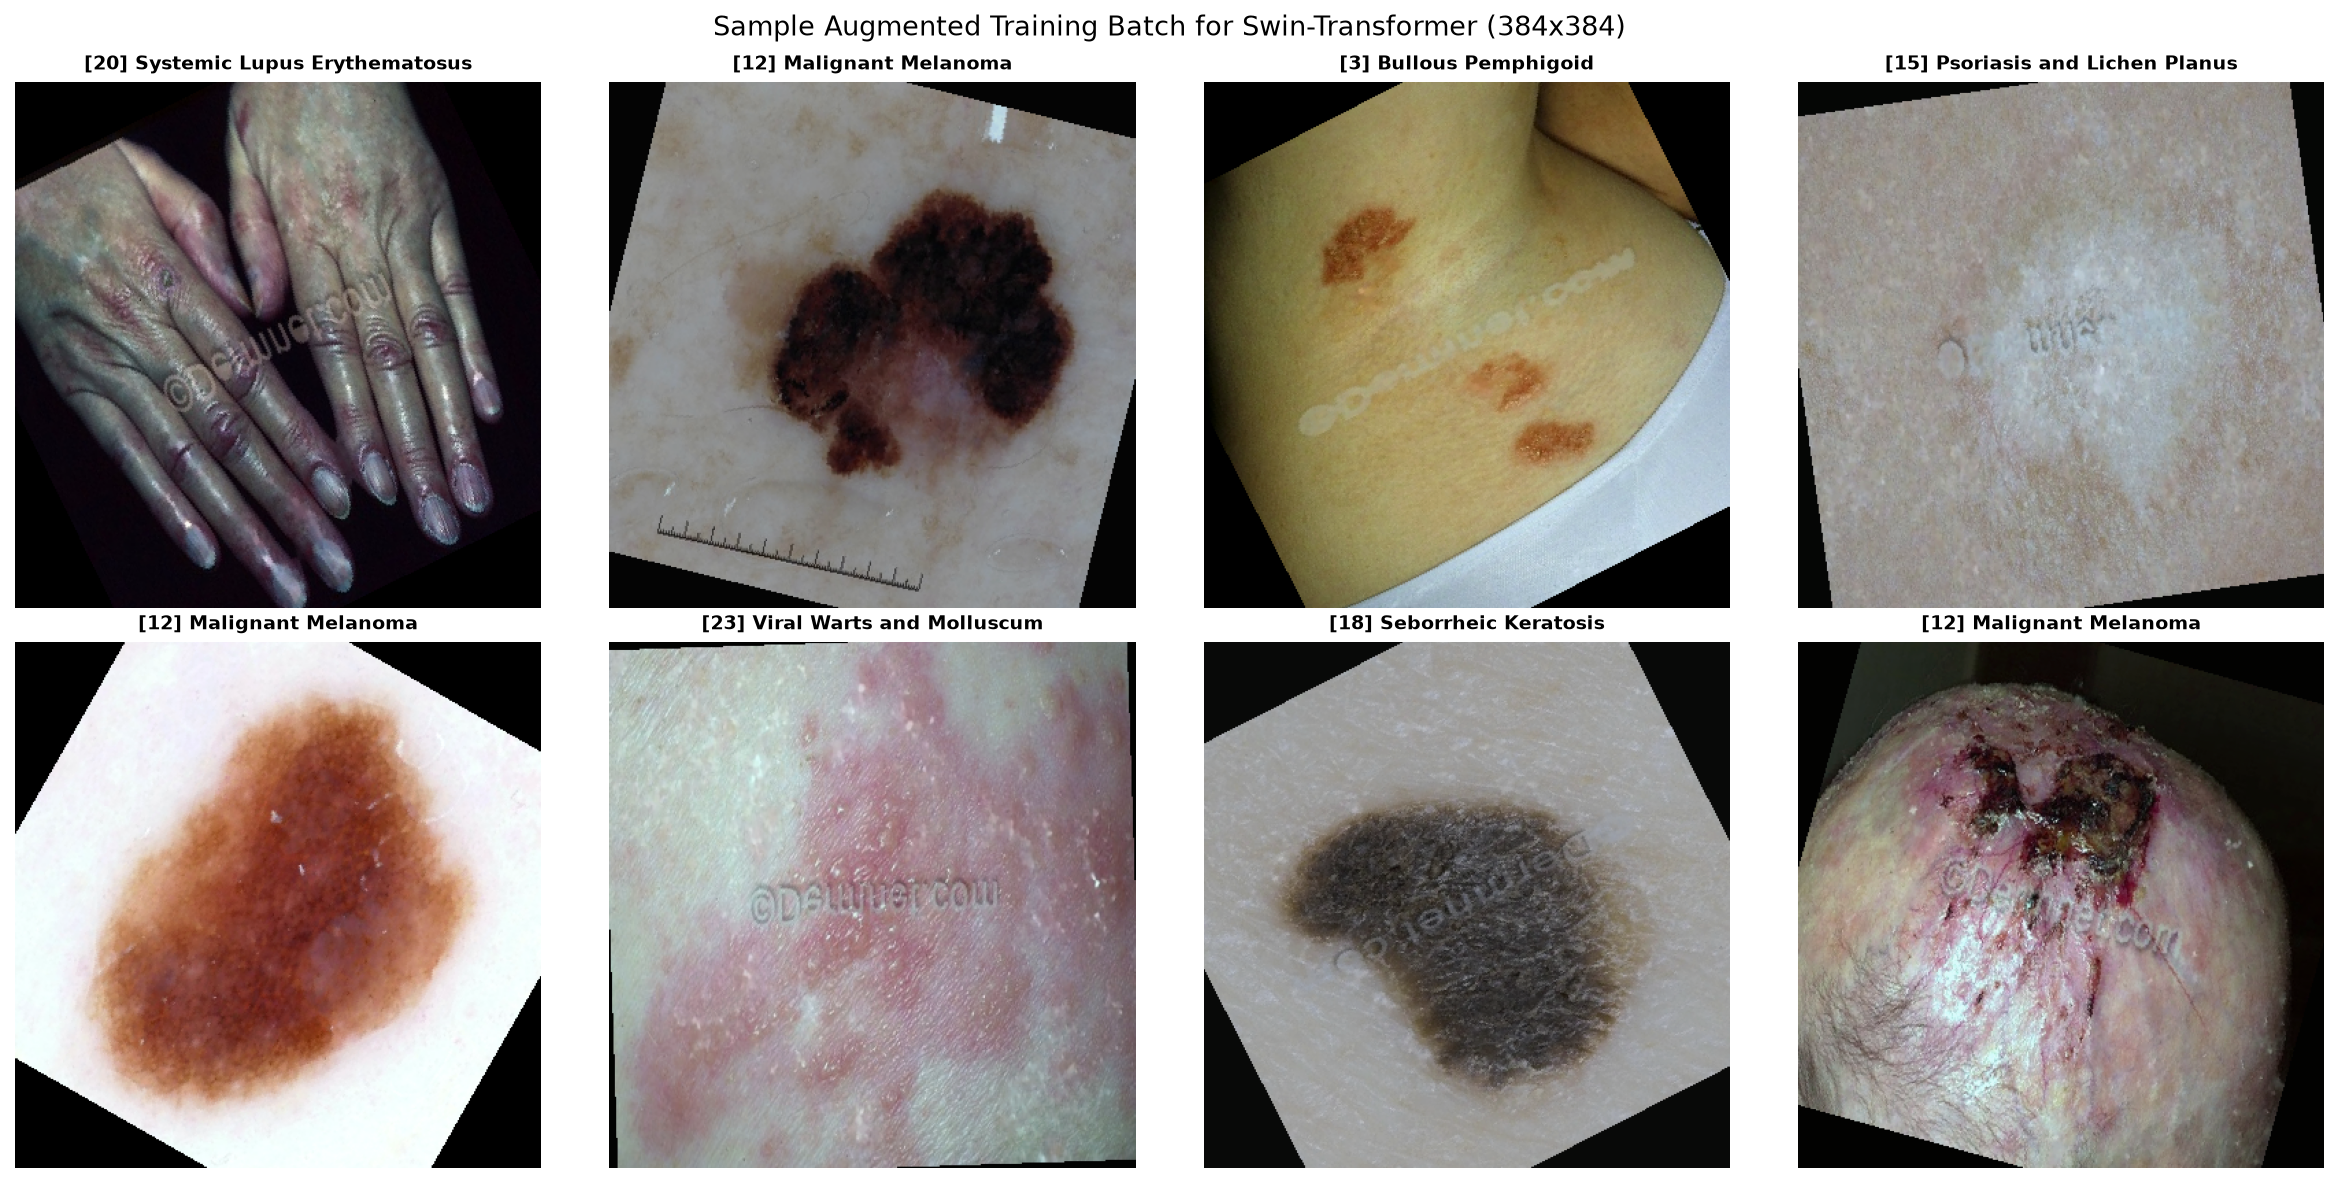

Ready for Cell 3: Swin Transformer Architecture & Shifted Window Optimization.


In [3]:
# ==============================================================================
# CELL 2: CLINICAL AUGMENTATIONS, CLASS-BALANCED WEIGHTS & DATALOADERS
# ==============================================================================
import os
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("=" * 80)
print("  BUILDING CLINICAL DATA PIPELINE & CLASS-BALANCED WEIGHTS")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Label Mapping & Clinical Acuity Tier Loading
# ------------------------------------------------------------------------------
label_map_path = os.path.join(PROJECT_ROOT, "metadata", "unified_label_map.json")
with open(label_map_path, "r") as f:
    LABEL_TO_ID = json.load(f)

ID_TO_LABEL = {v: k for k, v in LABEL_TO_ID.items()}
CLASS_NAMES = [ID_TO_LABEL[i] for i in range(CONFIG["num_classes"])]

# Clinical Acuity Tier Lookup from test manifest
CLASS_TIERS = dict(zip(df_test_meta["unified_class"], df_test_meta["clinical_tier"]))

print(f"✓ Diagnostic Categories Loaded : {len(LABEL_TO_ID)} classes")
print(f"✓ Acuity Tiers Mapped          : {len(CLASS_TIERS)} categories")

# ------------------------------------------------------------------------------
# 2. Cui et al. Class-Balanced Effective Sample Weights (Beta = 0.999)
# ------------------------------------------------------------------------------
train_counts = df_train_meta["unified_class"].value_counts()
class_frequencies = [train_counts.get(ID_TO_LABEL[i], 1) for i in range(CONFIG["num_classes"])]

beta = 0.999
effective_num = [1.0 - (beta ** n) for n in class_frequencies]
weights = [(1.0 - beta) / en for en in effective_num]

# Normalize so mean weight equals 1.0
weights = np.array(weights, dtype=np.float32)
weights = weights / weights.mean()
CLASS_WEIGHTS = torch.tensor(weights, dtype=torch.float32).to(DEVICE)

print(f"✓ Class Weights Computed       : Scaled from {weights.min():.2f}x (Melanoma) to {weights.max():.2f}x (Kaposi Sarcoma)")

# ------------------------------------------------------------------------------
# 3. Vision Transformer Augmentation Pipelines
# ------------------------------------------------------------------------------
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# ------------------------------------------------------------------------------
# 4. PyTorch Clinical Dataset Class (with Absolute Path Resolution)
# ------------------------------------------------------------------------------
class ClinicalDermatologyDataset(Dataset):
    """
    High-throughput PyTorch Dataset streaming preprocessed 384x384 clinical images
    directly from SSD with zero inpainting CPU overhead.
    """
    def __init__(self, manifest_df, root_dir, transform=None):
        self.manifest = manifest_df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]
        
        # Resolve absolute path to preprocessed 384 cache
        rel_proc_path = row.get("processed_path", "")
        if rel_proc_path and not os.path.isabs(rel_proc_path):
            img_path = os.path.join(self.root_dir, rel_proc_path)
        else:
            img_path = rel_proc_path

        try:
            image = Image.open(img_path).convert("RGB")
        except Exception:
            # Fallback to original file_path if preprocessed cache missing
            rel_orig_path = row["file_path"]
            if not os.path.isabs(rel_orig_path):
                fallback_path = os.path.join(self.root_dir, rel_orig_path)
            else:
                fallback_path = rel_orig_path
            image = Image.open(fallback_path).convert("RGB")
            image = image.resize((384, 384), Image.Resampling.LANCZOS)

        label = int(row["class_id"])

        if self.transform:
            image = self.transform(image)

        return image, label

# ------------------------------------------------------------------------------
# 5. Instantiate Datasets and DataLoaders (Windows Safe: num_workers=0)
# ------------------------------------------------------------------------------
train_dataset = ClinicalDermatologyDataset(df_train_meta, root_dir=PROJECT_ROOT, transform=train_transforms)
val_dataset = ClinicalDermatologyDataset(df_val_meta, root_dir=PROJECT_ROOT, transform=eval_transforms)
test_dataset = ClinicalDermatologyDataset(df_test_meta, root_dir=PROJECT_ROOT, transform=eval_transforms)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda")
)

print(f"✓ Train DataLoader Created     : {len(train_loader):,} batches ({len(train_dataset):,} images)")
print(f"✓ Val DataLoader Created       : {len(val_loader):,} batches ({len(val_dataset):,} images)")
print(f"✓ Test DataLoader Created      : {len(test_loader):,} batches ({len(test_dataset):,} images)")

# ------------------------------------------------------------------------------
# 6. Preview Sample Augmented Batch
# ------------------------------------------------------------------------------
sample_imgs, sample_labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(16, 8), dpi=150)
inv_normalize = transforms.Normalize(
    mean=[-m/s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)],
    std=[1/s for s in IMAGENET_STD]
)

for idx in range(8):
    ax = axes[idx // 4, idx % 4]
    img = inv_normalize(sample_imgs[idx]).clamp(0, 1).permute(1, 2, 0).cpu().numpy()
    lbl_id = sample_labels[idx].item()
    c_name = ID_TO_LABEL[lbl_id].replace("_", " ")
    
    ax.imshow(img)
    ax.set_title(f"[{lbl_id}] {c_name}", fontsize=9, fontweight="bold")
    ax.axis("off")

plt.suptitle("Sample Augmented Training Batch for Swin-Transformer (384x384)", fontsize=13, y=0.98)
plt.tight_layout()
plt.show()

print("=" * 80)
print("Ready for Cell 3: Swin Transformer Architecture & Shifted Window Optimization.")

In [4]:
# ==============================================================================
# CELL 3: SWIN-TRANSFORMER ARCHITECTURE, CLINICAL HEAD & FOCAL LOSS INITIALIZATION
# ==============================================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR

print("=" * 80)
print("  INITIALIZING SWIN-TRANSFORMER CLINICAL ARCHITECTURE & OPTIMIZATION")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Swin-T Backbone & Custom Clinical Classification Head
# ------------------------------------------------------------------------------
# Load official ImageNet-1K pretrained Swin Transformer Tiny weights
weights = models.Swin_T_Weights.IMAGENET1K_V1
model = models.swin_t(weights=weights)

# Inspect feature dimension entering the classification head (768 for swin_t)
in_features = model.head.in_features

# Custom two-stage regularized dermatological head
model.head = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, 512),
    nn.GELU(),
    nn.BatchNorm1d(512),
    nn.Dropout(p=0.2),
    nn.Linear(512, CONFIG["num_classes"])
)

# Transfer model to RTX 5050 GPU
model = model.to(DEVICE)

# Calculate parameter totals
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✓ Model Backbone Loaded       : Swin-Transformer Tiny (Shifted Window Attention, W=7)")
print(f"✓ Custom Classifier Head     : Linear(768->512) -> GELU -> BN -> Linear(512->{CONFIG['num_classes']})")
print(f"✓ Total Parameters           : {total_params:,} ({total_params * 4 / (1024**2):.2f} MB float32)")
print(f"✓ Trainable Parameters       : {trainable_params:,} (100% End-to-End Fine-Tuning)")

# ------------------------------------------------------------------------------
# 2. Class-Balanced Focal Loss with Label Smoothing
# ------------------------------------------------------------------------------
class ClassBalancedFocalLoss(nn.Module):
    """
    Combines Cui et al. Class-Balanced Effective Sample Weights with Lin et al.
    Focal Loss and Label Smoothing for severe dermatological class imbalance.
    """
    def __init__(self, alpha_weights=None, gamma=2.0, label_smoothing=0.1):
        super(ClassBalancedFocalLoss, self).__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        if alpha_weights is not None:
            self.register_buffer("alpha_weights", alpha_weights)
        else:
            self.alpha_weights = None

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(
            logits, 
            targets, 
            reduction="none", 
            label_smoothing=self.label_smoothing
        )
        pt = torch.exp(-ce_loss)
        focal_term = (1.0 - pt) ** self.gamma
        
        if self.alpha_weights is not None:
            alpha_t = self.alpha_weights[targets]
            loss = alpha_t * focal_term * ce_loss
        else:
            loss = focal_term * ce_loss
            
        return loss.mean()

criterion = ClassBalancedFocalLoss(
    alpha_weights=CLASS_WEIGHTS,
    gamma=2.0,
    label_smoothing=CONFIG["label_smoothing"]
)
print(f"✓ Loss Criterion Configured  : Class-Balanced Focal Loss (gamma=2.0, smoothing={CONFIG['label_smoothing']})")

# ------------------------------------------------------------------------------
# 3. AdamW Optimizer & Warmup Cosine Annealing Scheduler
# ------------------------------------------------------------------------------
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)

warmup_scheduler = LinearLR(
    optimizer,
    start_factor=0.01,
    end_factor=1.0,
    total_iters=CONFIG["warmup_epochs"]
)

cosine_scheduler = CosineAnnealingLR(
    optimizer,
    T_max=(CONFIG["epochs"] - CONFIG["warmup_epochs"]),
    eta_min=CONFIG["min_lr"]
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[CONFIG["warmup_epochs"]]
)

print(f"✓ Optimizer Instantiated     : AdamW (lr={CONFIG['learning_rate']}, weight_decay={CONFIG['weight_decay']})")
print(f"✓ Learning Rate Scheduler    : SequentialLR (Warmup {CONFIG['warmup_epochs']} eps -> CosineAnnealing to {CONFIG['min_lr']})")

# ------------------------------------------------------------------------------
# 4. Mixed Precision Scaler for RTX 5050 Tensor Cores
# ------------------------------------------------------------------------------
scaler = torch.amp.GradScaler("cuda", enabled=CONFIG["mixed_precision"])
print(f"✓ PyTorch AMP GradScaler     : Enabled (torch.amp for RTX 5050 Blackwell)")

# ------------------------------------------------------------------------------
# 5. Architecture Smoke Test (Forward Pass with Synthetic Batch)
# ------------------------------------------------------------------------------
print("-" * 80)
print("  RUNNING SWIN-T ARCHITECTURE & VRAM SMOKE TEST...")
with torch.no_grad():
    dummy_input = torch.randn(CONFIG["batch_size"], 3, *CONFIG["input_size"], device=DEVICE)
    with torch.amp.autocast("cuda", enabled=CONFIG["mixed_precision"]):
        dummy_output = model(dummy_input)
        dummy_targets = torch.randint(0, CONFIG["num_classes"], (CONFIG["batch_size"],), device=DEVICE)
        dummy_loss = criterion(dummy_output, dummy_targets)

vram_allocated_mb = torch.cuda.memory_allocated(DEVICE) / (1024 ** 2)
vram_reserved_mb = torch.cuda.memory_reserved(DEVICE) / (1024 ** 2)

print(f"✓ Smoke Test Input Tensor    : {tuple(dummy_input.shape)} on {DEVICE}")
print(f"✓ Smoke Test Output Logits   : {tuple(dummy_output.shape)} (Expected [16, 25])")
print(f"✓ Smoke Test Loss Evaluation : {dummy_loss.item():.4f}")
print(f"✓ Active GPU VRAM Allocation : {vram_allocated_mb:.1f} MB allocated | {vram_reserved_mb:.1f} MB reserved")
print("=" * 80)
print("Ready for Cell 4: Swin-T Resumable Training Engine.")

  INITIALIZING SWIN-TRANSFORMER CLINICAL ARCHITECTURE & OPTIMIZATION
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to C:\Users\kvcsu_ht23nk8/.cache\torch\hub\checkpoints\swin_t-704ceda3.pth


100%|██████████| 108M/108M [01:44<00:00, 1.09MB/s] 


✓ Model Backbone Loaded       : Swin-Transformer Tiny (Shifted Window Attention, W=7)
✓ Custom Classifier Head     : Linear(768->512) -> GELU -> BN -> Linear(512->25)
✓ Total Parameters           : 27,926,931 (106.53 MB float32)
✓ Trainable Parameters       : 27,926,931 (100% End-to-End Fine-Tuning)
✓ Loss Criterion Configured  : Class-Balanced Focal Loss (gamma=2.0, smoothing=0.1)
✓ Optimizer Instantiated     : AdamW (lr=0.0001, weight_decay=0.05)
✓ Learning Rate Scheduler    : SequentialLR (Warmup 2 eps -> CosineAnnealing to 1e-06)
✓ PyTorch AMP GradScaler     : Enabled (torch.amp for RTX 5050 Blackwell)
--------------------------------------------------------------------------------
  RUNNING SWIN-T ARCHITECTURE & VRAM SMOKE TEST...
✓ Smoke Test Input Tensor    : (16, 3, 384, 384) on cuda
✓ Smoke Test Output Logits   : (16, 25) (Expected [16, 25])
✓ Smoke Test Loss Evaluation : 3.4889
✓ Active GPU VRAM Allocation : 144.7 MB allocated | 1054.0 MB reserved
Ready for Cell 4: Swin-T Res

In [6]:
# ==============================================================================
# CELL 4: MODULAR RESUMABLE TRAINING, VALIDATION & LOGGING PIPELINE (SWIN-T)
# ==============================================================================
import os
import json
import time
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.metrics import f1_score

print("=" * 80)
print("  STARTING SWIN-TRANSFORMER RESUMABLE TRAINING ENGINE")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Path Resolution & Directory Setup
# ------------------------------------------------------------------------------
checkpoints_dir = CONFIG.get("checkpoints_dir", os.path.join(PROJECT_ROOT, "Models", "checkpoints", "swin_tiny"))
logs_dir = CONFIG.get("logs_dir", os.path.join(PROJECT_ROOT, "Models", "logs", "swin_tiny"))

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(logs_dir, exist_ok=True)

last_ckpt_path = CONFIG.get("last_checkpoint_path", os.path.join(checkpoints_dir, "last_checkpoint.pth"))
best_model_path = CONFIG.get("best_checkpoint_path", os.path.join(checkpoints_dir, "best_swin_tiny.pth"))
metrics_csv_path = os.path.join(logs_dir, "training_metrics.csv")
logs_json_path = os.path.join(logs_dir, "training_logs.json")

print(f"✓ Checkpoints Directory     : {checkpoints_dir}")
print(f"✓ Logs Directory            : {logs_dir}")
print(f"✓ Checkpoint Target (Last)  : {last_ckpt_path}")
print(f"✓ Checkpoint Target (Best)  : {best_model_path}")
print(f"✓ Metrics CSV Log Target    : {metrics_csv_path}")
print(f"✓ Telemetry JSON Log Target : {logs_json_path}")

# ------------------------------------------------------------------------------
# 2. Modular Helper: Training Step (One Epoch)
# ------------------------------------------------------------------------------
def train_one_epoch(model, dataloader, criterion, optimizer, scaler, device, config, current_epoch):
    """Executes single training epoch with AMP autocast and gradient clipping."""
    model.train()
    running_loss = 0.0
    total_samples = 0
    current_lr = optimizer.param_groups[0]["lr"]

    pbar = tqdm(
        dataloader, 
        desc=f"Epoch [{current_epoch:02d}/{config['epochs']:02d}] Train", 
        leave=False,
        dynamic_ncols=True
    )

    for imgs, labels in pbar:
        imgs = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # PyTorch Modern AMP autocast syntax for Blackwell / RTX 5050
        with torch.amp.autocast("cuda", enabled=config["mixed_precision"]):
            logits = model(imgs)
            loss = criterion(logits, labels)

        # Scaled backward pass & gradient clipping
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=config["grad_clip_norm"])
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

        pbar.set_postfix({"loss": f"{loss.item():.4f}", "lr": f"{current_lr:.1e}"})

    epoch_loss = running_loss / total_samples
    return epoch_loss, current_lr

# ------------------------------------------------------------------------------
# 3. Modular Helper: Validation Step (One Epoch)
# ------------------------------------------------------------------------------
def validate_one_epoch(model, dataloader, criterion, device, config, current_epoch):
    """Evaluates validation loss, Top-1 accuracy, Top-3 accuracy and Macro-F1."""
    model.eval()
    running_loss = 0.0
    total_samples = 0
    all_preds = []
    all_targets = []
    top3_correct = 0

    pbar = tqdm(
        dataloader, 
        desc=f"Epoch [{current_epoch:02d}/{config['epochs']:02d}] Val  ", 
        leave=False,
        dynamic_ncols=True
    )

    with torch.no_grad():
        for imgs, labels in pbar:
            imgs = imgs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=config["mixed_precision"]):
                logits = model(imgs)
                loss = criterion(logits, labels)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

            # Top-1 Predictions
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

            # Top-3 Differential Predictions
            _, top3_indices = torch.topk(logits, k=3, dim=1)
            top3_correct += (top3_indices == labels.unsqueeze(1)).any(dim=1).sum().item()

            pbar.set_postfix({"loss": f"{loss.item():.4f}"})

    val_loss = running_loss / total_samples
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)

    top1_acc = (all_preds == all_targets).mean() * 100.0
    top3_acc = (top3_correct / total_samples) * 100.0
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0) * 100.0

    return val_loss, top1_acc, top3_acc, macro_f1

# ------------------------------------------------------------------------------
# 4. Modular Helper: Log Persistence (CSV & Structured JSON)
# ------------------------------------------------------------------------------
def save_training_logs(epoch_records, best_metadata, csv_path, json_path):
    """Synchronizes epoch logs to CSV and structured JSON files."""
    # 1. Export CSV
    df = pd.DataFrame(epoch_records)
    df.to_csv(csv_path, index=False)

    # 2. Export Structured JSON
    payload = {
        "metadata": {
            "model_name": CONFIG.get("model_name", "swin_tiny"),
            "num_classes": CONFIG["num_classes"],
            "best_epoch": best_metadata["best_epoch"],
            "best_val_macro_f1": best_metadata["best_val_macro_f1"],
            "best_val_top1_acc": best_metadata["best_val_top1_acc"],
            "total_epochs_completed": len(epoch_records),
            "last_updated": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        },
        "epochs": epoch_records
    }
    with open(json_path, "w") as f:
        json.dump(payload, f, indent=4)

# ------------------------------------------------------------------------------
# 5. State Initialization & Resumption Logic
# ------------------------------------------------------------------------------
start_epoch = 1
best_val_f1 = 0.0
best_epoch_idx = 0
best_val_top1 = 0.0
epoch_records = []

if CONFIG.get("resume", True) and os.path.exists(last_ckpt_path):
    print(f"🔄 Existing Swin-T checkpoint detected at: {last_ckpt_path}")
    checkpoint = torch.load(last_ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_val_f1 = checkpoint.get("best_val_f1", 0.0)
    best_epoch_idx = checkpoint.get("best_epoch", 0)
    epoch_records = checkpoint.get("epoch_records", [])
    print(f"✓ Resumed from Epoch {start_epoch - 1} | Best Macro-F1 so far: {best_val_f1:.2f}% (Epoch {best_epoch_idx})")
else:
    print(f"✓ Clean initialization: Starting from Epoch 1 (Target: {CONFIG['epochs']} epochs)")

print("-" * 80)

# ------------------------------------------------------------------------------
# 6. Main Pipeline Execution
# ------------------------------------------------------------------------------
pipeline_start_time = time.time()

try:
    for epoch in range(start_epoch, CONFIG["epochs"] + 1):
        t0 = time.time()

        # Step 1: Train
        train_loss, current_lr = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, DEVICE, CONFIG, epoch
        )

        # Step 2: Validate
        val_loss, val_acc, top3_acc, macro_f1 = validate_one_epoch(
            model, val_loader, criterion, DEVICE, CONFIG, epoch
        )

        # Step 3: Advance Scheduler
        scheduler.step()

        # Step 4: Check if current epoch is the new best
        epoch_duration = round(time.time() - t0, 2)
        is_best = macro_f1 > best_val_f1
        marker = " "

        if is_best:
            best_val_f1 = macro_f1
            best_epoch_idx = epoch
            best_val_top1 = val_acc
            marker = " 🏆 (New Best!)"

        # Step 5: Record Epoch Telemetry
        epoch_entry = {
            "epoch": epoch,
            "duration_sec": epoch_duration,
            "train_loss": round(float(train_loss), 5),
            "val_loss": round(float(val_loss), 5),
            "val_top1_acc": round(float(val_acc), 3),
            "val_top3_acc": round(float(top3_acc), 3),
            "val_macro_f1": round(float(macro_f1), 3),
            "learning_rate": float(current_lr),
            "is_best": bool(is_best),
            "best_macro_f1_so_far": round(float(best_val_f1), 3),
            "best_epoch": int(best_epoch_idx),
            "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        }
        epoch_records.append(epoch_entry)

        # Step 6: Package Complete Resumable State
        checkpoint_state = {
            "epoch": epoch,
            "best_epoch": best_epoch_idx,
            "best_val_f1": best_val_f1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "epoch_records": epoch_records,
            "config": CONFIG
        }

        # Step 7: Persist Checkpoints
        # Always update last checkpoint for seamless resumption
        torch.save(checkpoint_state, last_ckpt_path)

        # Save best checkpoint when new high-water mark reached
        if is_best:
            torch.save(checkpoint_state, best_model_path)

        # Step 8: Persist CSV and JSON Logs
        best_meta = {
            "best_epoch": best_epoch_idx,
            "best_val_macro_f1": round(float(best_val_f1), 3),
            "best_val_top1_acc": round(float(best_val_top1), 3)
        }
        save_training_logs(epoch_records, best_meta, metrics_csv_path, logs_json_path)

        # Console Summary Row
        print(
            f"Epoch [{epoch:02d}/{CONFIG['epochs']:02d}] "
            f"({epoch_duration}s) | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Top-3: {top3_acc:.2f}% | "
            f"Macro-F1: {macro_f1:.2f}% | "
            f"LR: {current_lr:.1e}{marker}"
        )

except KeyboardInterrupt:
    print("\n⚠️ Training halted by user. Latest epoch state and logs were safely preserved.")
    print(f"✓ Re-running this cell will automatically resume from Epoch {epoch}.")

total_runtime_min = (time.time() - pipeline_start_time) / 60
print("-" * 80)
print(f"✓ Training Pipeline Concluded in {total_runtime_min:.2f} minutes")
print(f"✓ Peak Validation Macro-F1    : {best_val_f1:.2f}% (Achieved at Epoch {best_epoch_idx})")
print(f"✓ Best Model Checkpoint Saved : {best_model_path}")
print(f"✓ Last Resumable Checkpoint   : {last_ckpt_path}")
print(f"✓ Metrics CSV Log Saved       : {metrics_csv_path}")
print(f"✓ Telemetry JSON Log Saved    : {logs_json_path}")
print("=" * 80)

c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  STARTING SWIN-TRANSFORMER RESUMABLE TRAINING ENGINE
✓ Checkpoints Directory     : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\swin_tiny
✓ Logs Directory            : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\logs\swin_tiny
✓ Checkpoint Target (Last)  : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\swin_tiny\last_checkpoint.pth
✓ Checkpoint Target (Best)  : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\swin_tiny\best_swin_tiny.pth
✓ Metrics CSV Log Target    : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\logs\swin_tiny\training_metrics.csv
✓ Telemetry JSON Log Target : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\logs

Epoch [01/25] (405.15s) | Train Loss: 1.4898 | Val Loss: 1.3773 | Val Acc: 11.93% | Top-3: 25.50% | Macro-F1: 6.80% | LR: 1.0e-06 🏆 (New Best!)


Epoch [02/25] (454.16s) | Train Loss: 1.1425 | Val Loss: 0.9268 | Val Acc: 42.81% | Top-3: 64.94% | Macro-F1: 34.01% | LR: 5.1e-05 🏆 (New Best!)


Epoch [03/25] (395.75s) | Train Loss: 0.9856 | Val Loss: 0.8758 | Val Acc: 45.12% | Top-3: 67.22% | Macro-F1: 39.11% | LR: 1.0e-04 🏆 (New Best!)


Epoch [04/25] (395.15s) | Train Loss: 0.8489 | Val Loss: 0.8065 | Val Acc: 49.44% | Top-3: 71.35% | Macro-F1: 41.55% | LR: 1.0e-04 🏆 (New Best!)


... (17 outputs left out)

Epoch [22/25] (394.95s) | Train Loss: 0.1638 | Val Loss: 0.5268 | Val Acc: 72.87% | Top-3: 88.53% | Macro-F1: 67.95% | LR: 8.2e-06 


Epoch [23/25] (394.61s) | Train Loss: 0.1611 | Val Loss: 0.5145 | Val Acc: 73.34% | Top-3: 87.96% | Macro-F1: 68.41% | LR: 5.1e-06 🏆 (New Best!)


Epoch [24/25] (394.69s) | Train Loss: 0.1579 | Val Loss: 0.5148 | Val Acc: 73.31% | Top-3: 88.23% | Macro-F1: 68.27% | LR: 2.8e-06 


Epoch [25/25] (394.16s) | Train Loss: 0.1526 | Val Loss: 0.5187 | Val Acc: 73.69% | Top-3: 88.37% | Macro-F1: 68.78% | LR: 1.5e-06 🏆 (New Best!)
--------------------------------------------------------------------------------
✓ Training Pipeline Concluded in 165.96 minutes
✓ Peak Validation Macro-F1    : 68.78% (Achieved at Epoch 25)
✓ Best Model Checkpoint Saved : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\swin_tiny\best_swin_tiny.pth
✓ Last Resumable Checkpoint   : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\swin_tiny\last_checkpoint.pth
✓ Metrics CSV Log Saved       : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\logs\swin_tiny\training_metrics.csv
✓ Telemetry JSON Log Saved    : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\logs\swin_tin

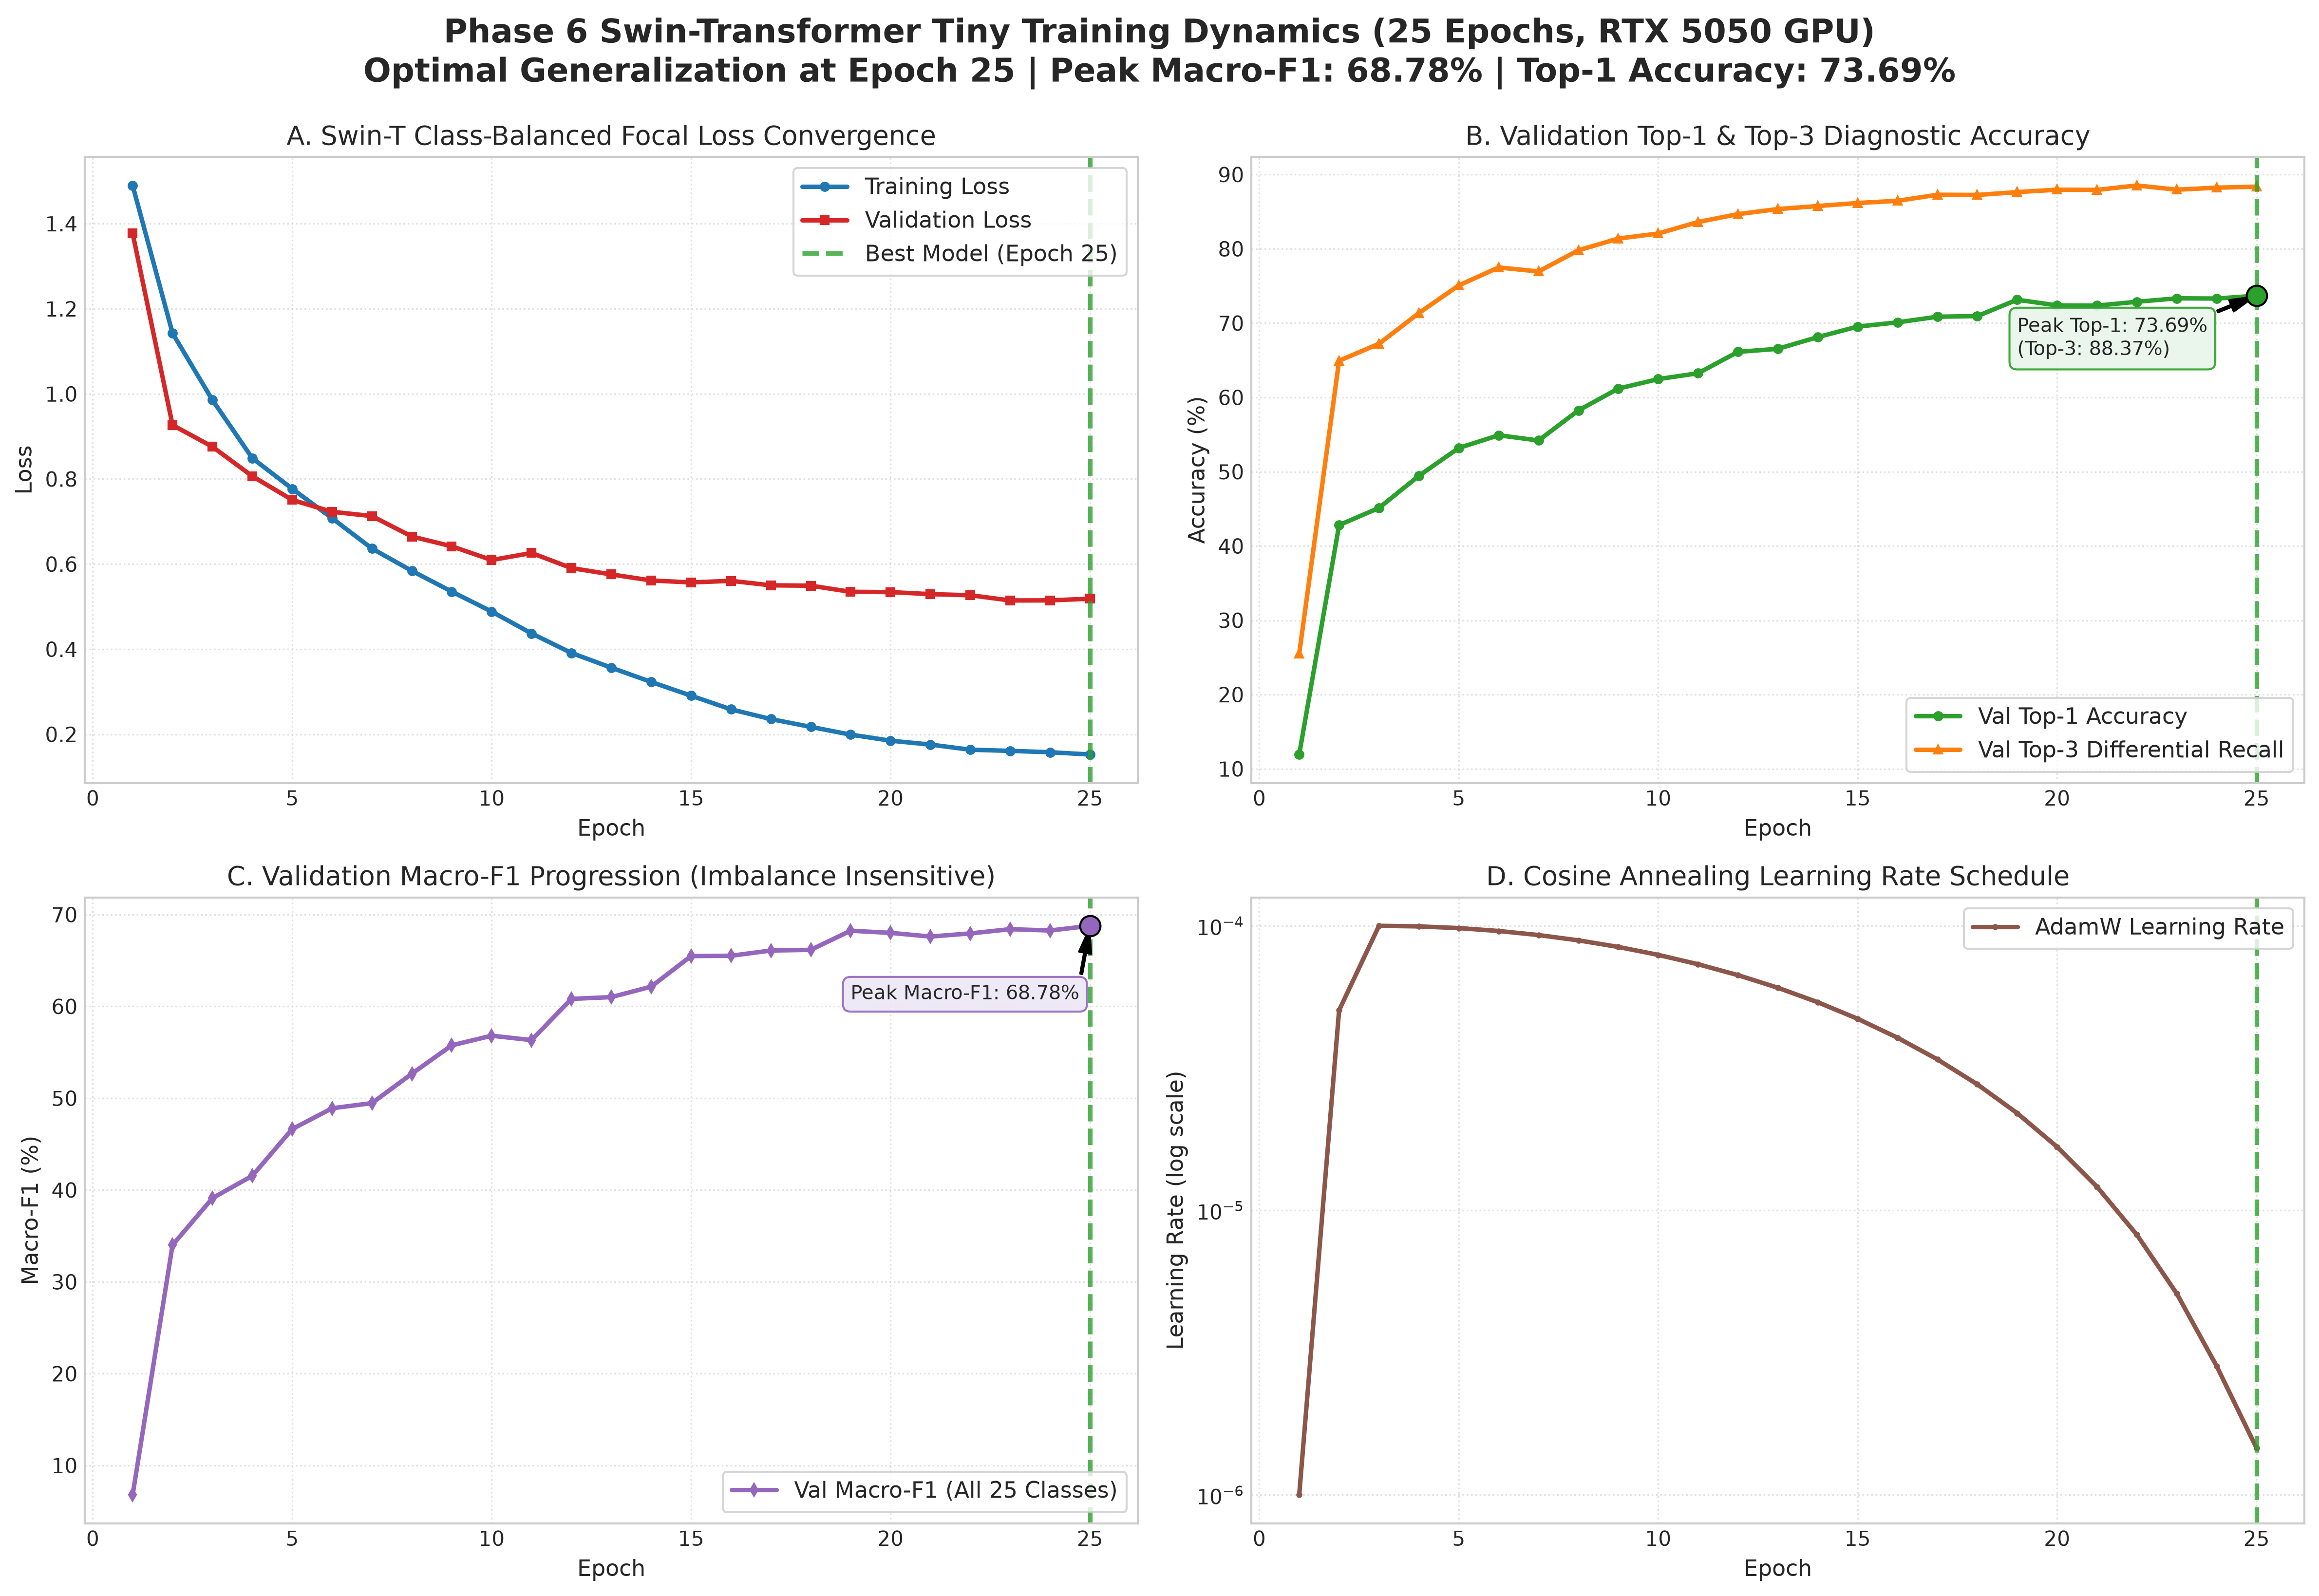

✓ Swin-T Training Curves Successfully Saved:
  --> c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\swin_training\01_swin_tiny_training_curves.png


In [4]:
# ==============================================================================
# CELL 5: VISUALIZING SWIN-TRANSFORMER TRAINING DYNAMICS & CONVERGENCE
# (Self-contained: Safe to run directly after kernel restart)
# ==============================================================================
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------------------
# 1. Self-Contained Path Resolution
# ------------------------------------------------------------------------------
cwd = os.getcwd()
if os.path.basename(cwd).lower() == "notebooks":
    PROJECT_ROOT = os.path.abspath(os.path.join(cwd, ".."))
else:
    PROJECT_ROOT = os.path.abspath(cwd)

logs_dir = os.path.join(PROJECT_ROOT, "Models", "logs", "swin_tiny")
plots_dir = os.path.join(PROJECT_ROOT, "results", "plots", "swin_training")
os.makedirs(plots_dir, exist_ok=True)

metrics_csv = os.path.join(logs_dir, "training_metrics.csv")
if not os.path.exists(metrics_csv):
    raise FileNotFoundError(f"Metrics CSV not found at: {metrics_csv}")

# ------------------------------------------------------------------------------
# 2. Configure Aesthetic Plotting Styling
# ------------------------------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 16,
    "lines.linewidth": 2.2
})

# ------------------------------------------------------------------------------
# 3. Load & Parse Metrics
# ------------------------------------------------------------------------------
df_metrics = pd.read_csv(metrics_csv)
best_epoch = int(df_metrics.loc[df_metrics["is_best"], "epoch"].max())
best_f1 = df_metrics.loc[df_metrics["epoch"] == best_epoch, "val_macro_f1"].values[0]
best_acc = df_metrics.loc[df_metrics["epoch"] == best_epoch, "val_top1_acc"].values[0]
best_top3 = df_metrics.loc[df_metrics["epoch"] == best_epoch, "val_top3_acc"].values[0]

epochs = df_metrics["epoch"]

# Setup 2x2 multi-panel diagnostic figure
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=300)

# ------------------------------------------------------------------------------
# Panel 1: Loss Progression (Focal Loss)
# ------------------------------------------------------------------------------
ax1 = axes[0, 0]
ax1.plot(epochs, df_metrics["train_loss"], label="Training Loss", color="#1f77b4", marker="o", markersize=4)
ax1.plot(epochs, df_metrics["val_loss"], label="Validation Loss", color="#d62728", marker="s", markersize=4)
ax1.axvline(x=best_epoch, color="#2ca02c", linestyle="--", alpha=0.8, label=f"Best Model (Epoch {best_epoch})")
ax1.set_title("A. Swin-T Class-Balanced Focal Loss Convergence")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Panel 2: Diagnostic Accuracy (Top-1 vs. Top-3 Differential Recall)
# ------------------------------------------------------------------------------
ax2 = axes[0, 1]
ax2.plot(epochs, df_metrics["val_top1_acc"], label="Val Top-1 Accuracy", color="#2ca02c", marker="o", markersize=4)
ax2.plot(epochs, df_metrics["val_top3_acc"], label="Val Top-3 Differential Recall", color="#ff7f0e", marker="^", markersize=4)
ax2.axvline(x=best_epoch, color="#2ca02c", linestyle="--", alpha=0.8)
ax2.scatter([best_epoch], [best_acc], color="#2ca02c", s=100, zorder=5, edgecolors="black")
ax2.annotate(
    f"Peak Top-1: {best_acc:.2f}%\n(Top-3: {best_top3:.2f}%)",
    xy=(best_epoch, best_acc),
    xytext=(best_epoch - 6, best_acc - 8),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    bbox=dict(boxstyle="round,pad=0.4", fc="#e8f5e9", ec="#2ca02c", alpha=0.9),
    fontsize=9.5
)
ax2.set_title("B. Validation Top-1 & Top-3 Diagnostic Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend(loc="lower right", frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Panel 3: Balanced Generalization Metric (25-Class Macro-F1)
# ------------------------------------------------------------------------------
ax3 = axes[1, 0]
ax3.plot(epochs, df_metrics["val_macro_f1"], label="Val Macro-F1 (All 25 Classes)", color="#9467bd", marker="d", markersize=4)
ax3.axvline(x=best_epoch, color="#2ca02c", linestyle="--", alpha=0.8)
ax3.scatter([best_epoch], [best_f1], color="#9467bd", s=100, zorder=5, edgecolors="black")
ax3.annotate(
    f"Peak Macro-F1: {best_f1:.2f}%",
    xy=(best_epoch, best_f1),
    xytext=(best_epoch - 6, best_f1 - 8),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    bbox=dict(boxstyle="round,pad=0.4", fc="#ede7f6", ec="#9467bd", alpha=0.9),
    fontsize=9.5
)
ax3.set_title("C. Validation Macro-F1 Progression (Imbalance Insensitive)")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Macro-F1 (%)")
ax3.legend(loc="lower right", frameon=True)
ax3.grid(True, linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Panel 4: Learning Rate Dynamics (Linear Warmup -> Cosine Decay)
# ------------------------------------------------------------------------------
ax4 = axes[1, 1]
ax4.plot(epochs, df_metrics["learning_rate"], label="AdamW Learning Rate", color="#8c564b", marker=".", markersize=4)
ax4.axvline(x=best_epoch, color="#2ca02c", linestyle="--", alpha=0.8)
ax4.set_yscale("log")
ax4.set_title("D. Cosine Annealing Learning Rate Schedule")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Learning Rate (log scale)")
ax4.legend(loc="upper right", frameon=True)
ax4.grid(True, linestyle=":", alpha=0.6)

plt.suptitle(
    "Phase 6 Swin-Transformer Tiny Training Dynamics (25 Epochs, RTX 5050 GPU)\n"
    f"Optimal Generalization at Epoch {best_epoch} | Peak Macro-F1: {best_f1:.2f}% | Top-1 Accuracy: {best_acc:.2f}%",
    y=0.99,
    fontweight="bold"
)

plt.tight_layout()

# Save high-resolution plot for thesis and report
plot_save_path = os.path.join(plots_dir, "01_swin_tiny_training_curves.png")
plt.savefig(plot_save_path, bbox_inches="tight")
plt.show()

print("=" * 80)
print(f"✓ Swin-T Training Curves Successfully Saved:")
print(f"  --> {plot_save_path}")
print("=" * 80)

  EVALUATING BEST SWIN-TRANSFORMER ON STRICTLY ISOLATED TEST HOLDOUT
Loading optimal Swin-T checkpoint from: c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\swin_tiny\best_swin_tiny.pth
✓ Loaded Best Model Weights (Trained to Epoch 25 | Peak Val Macro-F1: 68.78%)
Running inference across 4,599 test holdout images on cuda...
--------------------------------------------------------------------------------
✓ Swin-T Test Holdout Evaluation Complete (N = 4,599 images):
    - Test Top-1 Accuracy        : 72.86%
    - Test Top-3 Accuracy        : 87.82%
    - Test Macro-F1 (Balanced)   : 67.93%
    - Test Weighted-F1           : 72.73%
--------------------------------------------------------------------------------
CLINICAL ACUITY TIER AUDIT (SWIN-T):
  • Tier 1 (N = 1,317): Accuracy = 66.89% | Macro-F1 = 25.03%
  • Tier 2 (N = 3,282): Accuracy = 75.26% | Macro-F1 = 47.88%

✓ Saved Swin-T Classification Report to: c:\Users\kvcsu

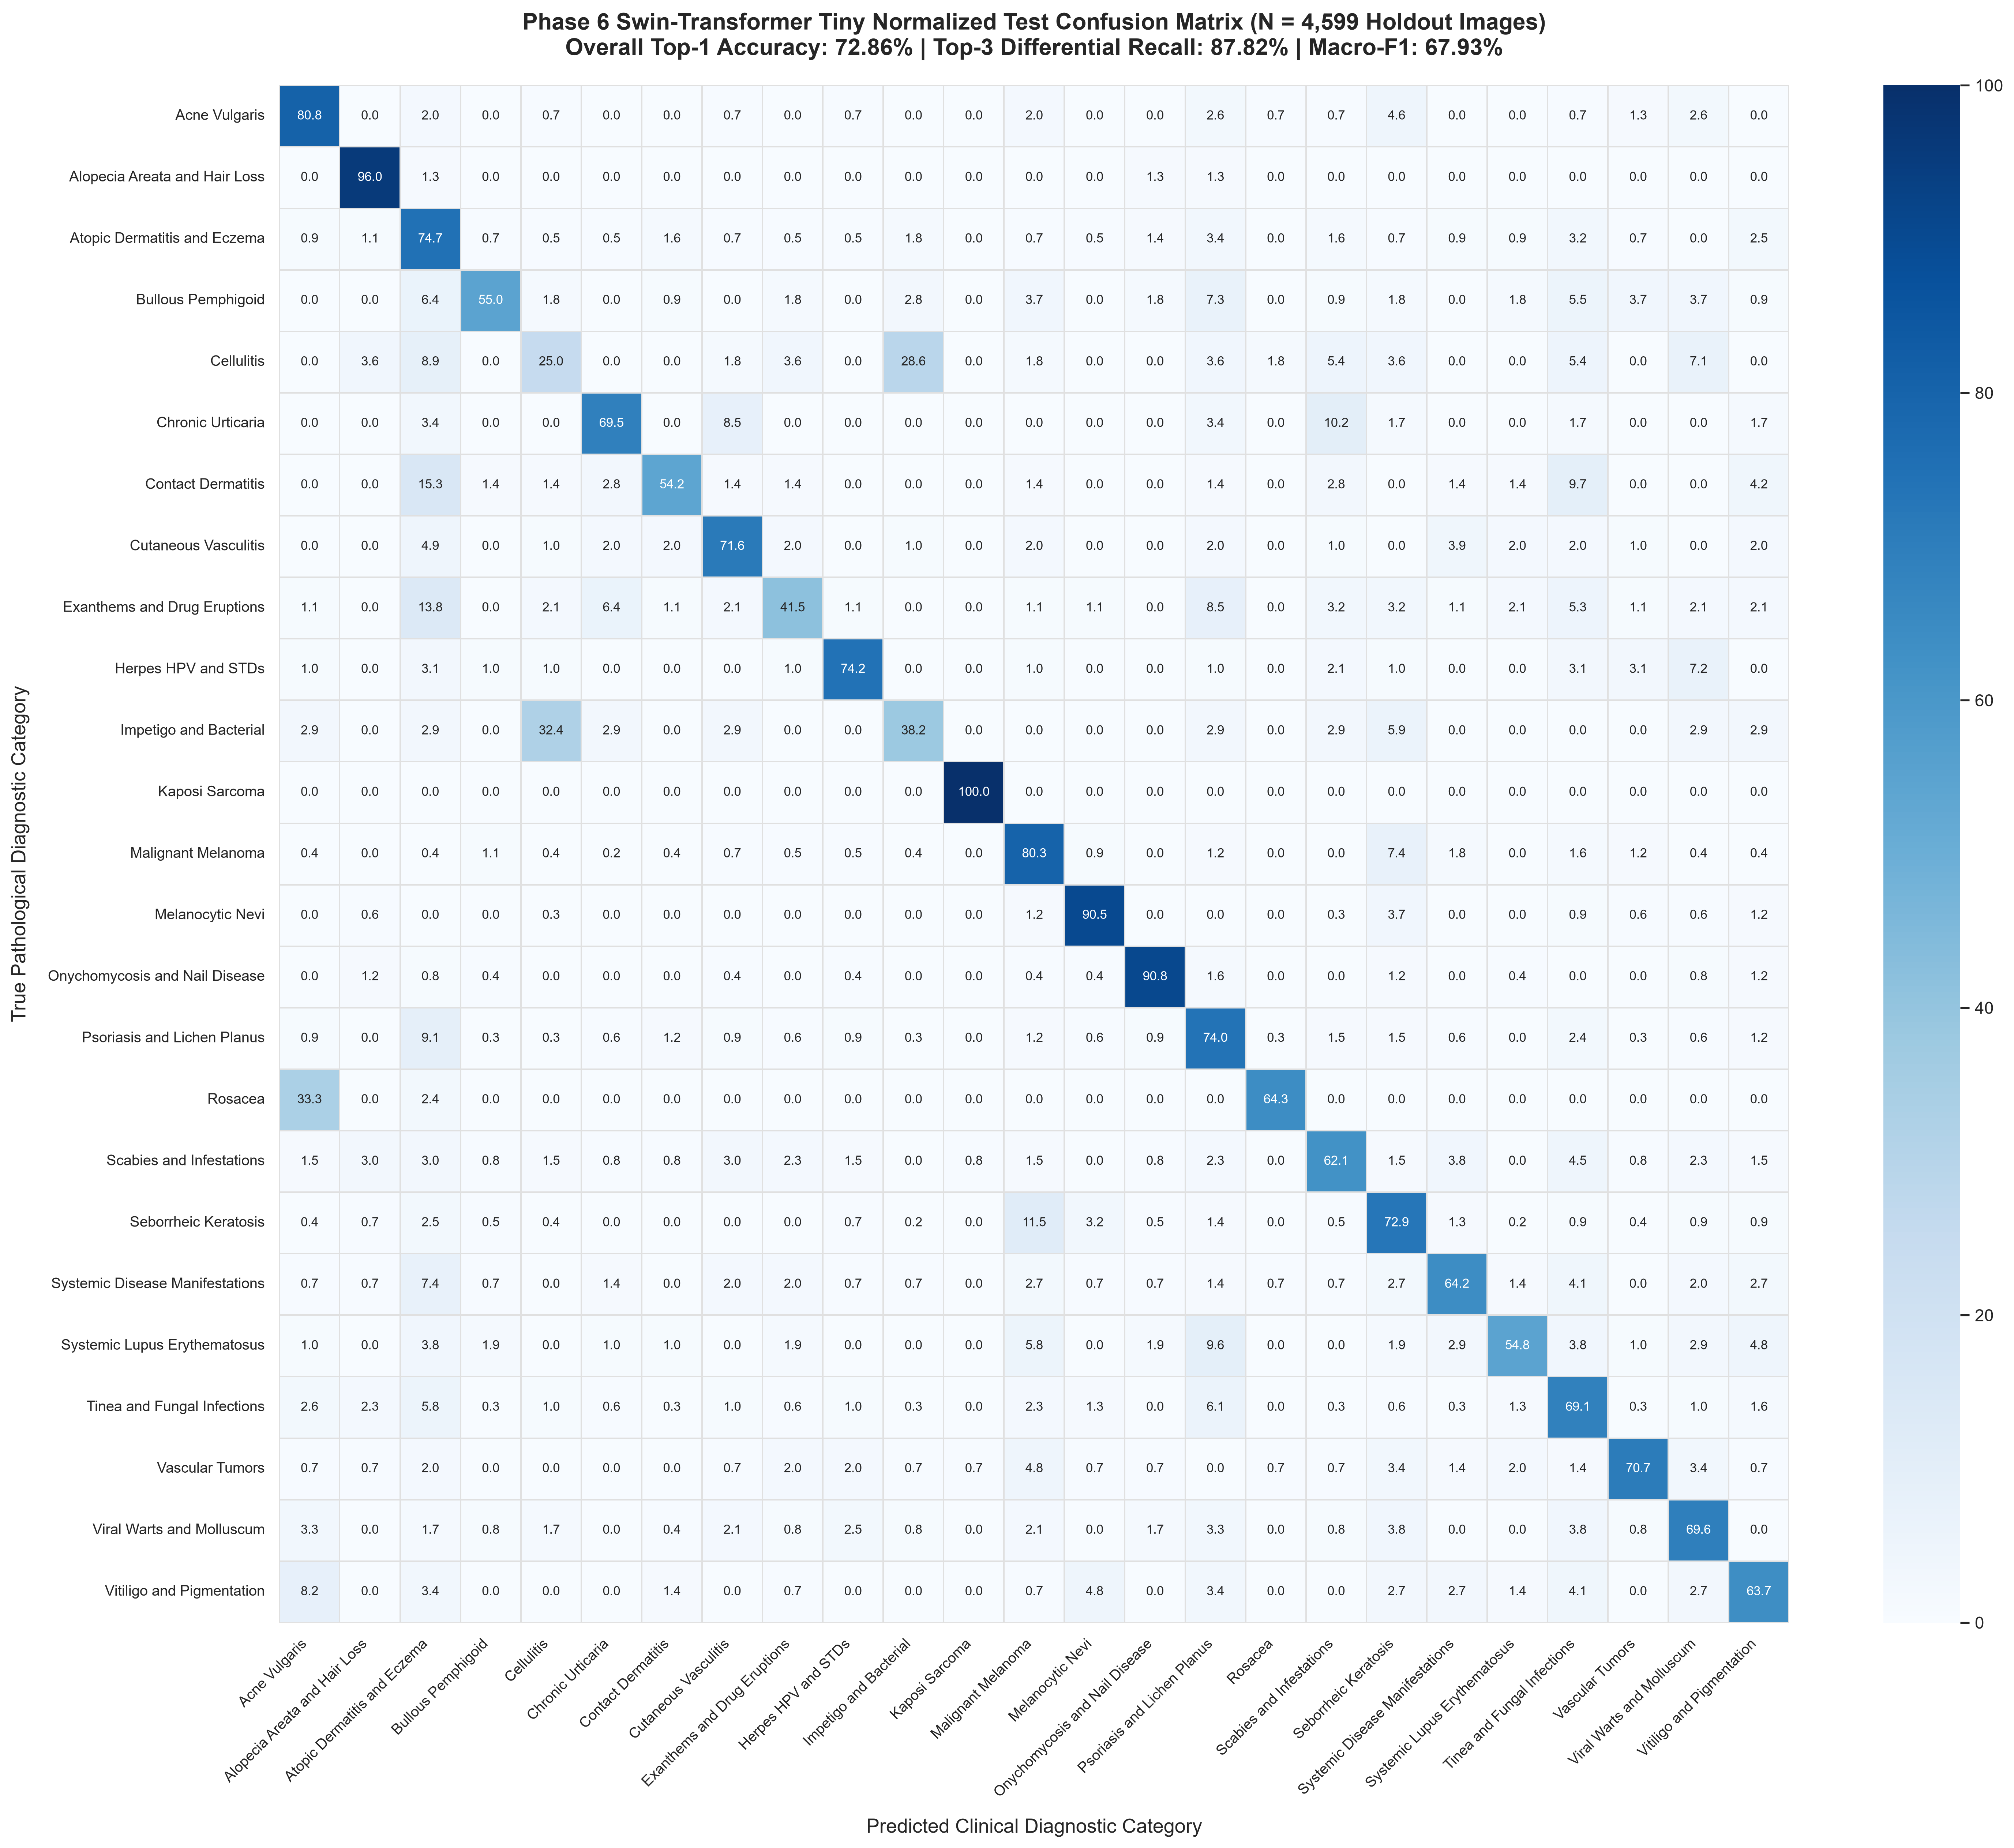

✓ Test Confusion Matrix Successfully Generated & Saved:
  --> c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\swin_training\02_swin_tiny_test_confusion_matrix.png
PHASE 6 COMPLETE: Ready to proceed to documentation and Phase 7 (Stacking Ensemble Fusion)!


In [5]:
# ==============================================================================
# CELL 6: UNBIASED EVALUATION ON ISOLATED TEST HOLDOUT (4,599 SAMPLES)
# (Self-contained: Safe to run directly after kernel restart)
# ==============================================================================
import os
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

print("=" * 80)
print("  EVALUATING BEST SWIN-TRANSFORMER ON STRICTLY ISOLATED TEST HOLDOUT")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Environment & Path Resolution
# ------------------------------------------------------------------------------
cwd = os.getcwd()
if os.path.basename(cwd).lower() == "notebooks":
    PROJECT_ROOT = os.path.abspath(os.path.join(cwd, ".."))
else:
    PROJECT_ROOT = os.path.abspath(cwd)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoints_dir = os.path.join(PROJECT_ROOT, "Models", "checkpoints", "swin_tiny")
logs_dir = os.path.join(PROJECT_ROOT, "Models", "logs", "swin_tiny")
plots_dir = os.path.join(PROJECT_ROOT, "results", "plots", "swin_training")
best_model_path = os.path.join(checkpoints_dir, "best_swin_tiny.pth")

os.makedirs(logs_dir, exist_ok=True)
os.makedirs(plots_dir, exist_ok=True)

# ------------------------------------------------------------------------------
# 2. Metadata & Label Mapping
# ------------------------------------------------------------------------------
label_map_path = os.path.join(PROJECT_ROOT, "metadata", "unified_label_map.json")
with open(label_map_path, "r") as f:
    LABEL_TO_ID = json.load(f)

ID_TO_LABEL = {v: k for k, v in LABEL_TO_ID.items()}
num_classes = len(LABEL_TO_ID)

test_manifest_path = os.path.join(PROJECT_ROOT, "metadata", "splits", "test_manifest.csv")
df_test = pd.read_csv(test_manifest_path)
CLASS_TIERS = dict(zip(df_test["unified_class"], df_test["clinical_tier"]))

# ------------------------------------------------------------------------------
# 3. Test Dataset & DataLoader
# ------------------------------------------------------------------------------
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

class ClinicalDermatologyDataset(Dataset):
    def __init__(self, manifest_df, root_dir, transform=None):
        self.manifest = manifest_df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]
        rel_proc_path = row.get("processed_path", "")
        if rel_proc_path and not os.path.isabs(rel_proc_path):
            img_path = os.path.join(self.root_dir, rel_proc_path)
        else:
            img_path = rel_proc_path

        try:
            image = Image.open(img_path).convert("RGB")
        except Exception:
            rel_orig_path = row["file_path"]
            fallback_path = os.path.join(self.root_dir, rel_orig_path) if not os.path.isabs(rel_orig_path) else rel_orig_path
            image = Image.open(fallback_path).convert("RGB")
            image = image.resize((384, 384), Image.Resampling.LANCZOS)

        label = int(row["class_id"])
        if self.transform:
            image = self.transform(image)
        return image, label

test_dataset = ClinicalDermatologyDataset(df_test, root_dir=PROJECT_ROOT, transform=eval_transforms)
test_loader = DataLoader(
    test_dataset, 
    batch_size=16, 
    shuffle=False, 
    num_workers=0, 
    pin_memory=(DEVICE.type == "cuda")
)

# ------------------------------------------------------------------------------
# 4. Reconstruct Architecture & Load Best Checkpoint
# ------------------------------------------------------------------------------
model = models.swin_t(weights=None)
in_features = model.head.in_features
model.head = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, 512),
    nn.GELU(),
    nn.BatchNorm1d(512),
    nn.Dropout(p=0.2),
    nn.Linear(512, num_classes)
)

print(f"Loading optimal Swin-T checkpoint from: {best_model_path}")
checkpoint = torch.load(best_model_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

best_epoch = checkpoint.get("best_epoch", checkpoint.get("epoch", "N/A"))
best_val_f1 = checkpoint.get("best_val_f1", 0.0)
print(f"✓ Loaded Best Model Weights (Trained to Epoch {best_epoch} | Peak Val Macro-F1: {best_val_f1:.2f}%)")

# ------------------------------------------------------------------------------
# 5. Batch Inference Across Isolated Test Holdout
# ------------------------------------------------------------------------------
all_test_preds = []
all_test_targets = []
all_test_probs = []
top3_correct = 0

print(f"Running inference across {len(test_dataset):,} test holdout images on {DEVICE}...")

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits = model(imgs)

        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        all_test_preds.extend(preds.cpu().numpy())
        all_test_targets.extend(labels.cpu().numpy())
        all_test_probs.extend(probs.cpu().numpy())

        _, top3_indices = torch.topk(logits, k=3, dim=1)
        top3_correct += (top3_indices == labels.unsqueeze(1)).any(dim=1).sum().item()

all_test_preds = np.array(all_test_preds)
all_test_targets = np.array(all_test_targets)
all_test_probs = np.array(all_test_probs)

test_top1_acc = (all_test_preds == all_test_targets).mean() * 100.0
test_top3_acc = (top3_correct / len(test_dataset)) * 100.0
test_macro_f1 = f1_score(all_test_targets, all_test_preds, average="macro", zero_division=0) * 100.0
test_weighted_f1 = f1_score(all_test_targets, all_test_preds, average="weighted", zero_division=0) * 100.0

print("-" * 80)
print(f"✓ Swin-T Test Holdout Evaluation Complete (N = {len(test_dataset):,} images):")
print(f"    - Test Top-1 Accuracy        : {test_top1_acc:.2f}%")
print(f"    - Test Top-3 Accuracy        : {test_top3_acc:.2f}%")
print(f"    - Test Macro-F1 (Balanced)   : {test_macro_f1:.2f}%")
print(f"    - Test Weighted-F1           : {test_weighted_f1:.2f}%")

# ------------------------------------------------------------------------------
# 6. Clinical Acuity Tier Performance
# ------------------------------------------------------------------------------
test_df = pd.DataFrame({
    "true_label": all_test_targets,
    "pred_label": all_test_preds,
    "correct": (all_test_preds == all_test_targets)
})
test_df["class_name"] = test_df["true_label"].map(ID_TO_LABEL)
test_df["tier"] = test_df["class_name"].map(CLASS_TIERS)

print("-" * 80)
print("CLINICAL ACUITY TIER AUDIT (SWIN-T):")
for tier_name in sorted(test_df["tier"].dropna().unique()):
    tier_subset = test_df[test_df["tier"] == tier_name]
    t_acc = tier_subset["correct"].mean() * 100.0
    t_f1 = f1_score(tier_subset["true_label"], tier_subset["pred_label"], average="macro", zero_division=0) * 100.0
    print(f"  • {tier_name} (N = {len(tier_subset):,}): Accuracy = {t_acc:.2f}% | Macro-F1 = {t_f1:.2f}%")

# ------------------------------------------------------------------------------
# 7. Generate & Save Per-Class Classification Report
# ------------------------------------------------------------------------------
target_names = [ID_TO_LABEL[i] for i in range(num_classes)]
report_dict = classification_report(
    all_test_targets, 
    all_test_preds, 
    target_names=target_names, 
    output_dict=True, 
    zero_division=0
)

df_report = pd.DataFrame(report_dict).transpose()
df_report["Tier"] = df_report.index.map(lambda x: CLASS_TIERS.get(x, ""))

report_save_path = os.path.join(logs_dir, "test_classification_report.csv")
df_report.to_csv(report_save_path)
print(f"\n✓ Saved Swin-T Classification Report to: {report_save_path}")

# Preview High-Risk Conditions
critical_classes = ["Malignant_Melanoma", "Bullous_Pemphigoid", "Cellulitis", "Kaposi_Sarcoma", "Cutaneous_Vasculitis"]
preview_df = df_report.loc[[c for c in critical_classes if c in df_report.index], ["precision", "recall", "f1-score", "support"]]
print("\nCritical High-Risk Lesions Audit Preview (Swin-T):")
print(preview_df.round(3).to_string())

# ------------------------------------------------------------------------------
# 8. Normalized 25-Class Confusion Matrix Heatmap
# ------------------------------------------------------------------------------
cm = confusion_matrix(all_test_targets, all_test_preds, normalize="true") * 100.0
clean_display_names = [name.replace("_", " ") for name in target_names]
cm_plot_path = os.path.join(plots_dir, "02_swin_tiny_test_confusion_matrix.png")

plt.figure(figsize=(20, 17), dpi=300)
sns.set_theme(style="white")

ax = sns.heatmap(
    cm, 
    annot=True, 
    fmt=".1f", 
    cmap="Blues", 
    cbar=True,
    xticklabels=clean_display_names, 
    yticklabels=clean_display_names,
    annot_kws={"size": 8.5},
    linewidths=0.5,
    linecolor="#e0e0e0"
)

plt.title(
    f"Phase 6 Swin-Transformer Tiny Normalized Test Confusion Matrix (N = {len(test_dataset):,} Holdout Images)\n"
    f"Overall Top-1 Accuracy: {test_top1_acc:.2f}% | Top-3 Differential Recall: {test_top3_acc:.2f}% | Macro-F1: {test_macro_f1:.2f}%",
    fontsize=15, 
    pad=20, 
    fontweight="bold"
)
plt.xlabel("Predicted Clinical Diagnostic Category", fontsize=13, labelpad=12)
plt.ylabel("True Pathological Diagnostic Category", fontsize=13, labelpad=12)
plt.xticks(rotation=45, ha="right", fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)

plt.tight_layout()
plt.savefig(cm_plot_path, bbox_inches="tight")
plt.show()

print("=" * 80)
print(f"✓ Test Confusion Matrix Successfully Generated & Saved:")
print(f"  --> {cm_plot_path}")
print("=" * 80)
print("PHASE 6 COMPLETE: Ready to proceed to documentation and Phase 7 (Stacking Ensemble Fusion)!")